# Number of copies


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.function_library import modified_zakharov, sigmoid
from utilities.orponet import OrPoNet
from utilities.residual_orponet import ResidualOrPoNet
from utilities.training import Trainer


## 1. Settings


In [2]:
DEVICE = torch.device("cpu")
DTYPE = torch.float32

torch.set_num_threads(1)


## 2. Data and model


In [3]:
DIMENSION = 10
TRAIN_SAMPLES = 4000
VALIDATION_SAMPLES = 4000


def sample_data(target, radius):
    engine = torch.quasirandom.SobolEngine(DIMENSION, scramble=False)
    # Preserve the source's float32 Sobol draw and float64 physical scaling.
    unit = engine.draw(TRAIN_SAMPLES + VALIDATION_SAMPLES).double()
    inputs = (radius * (2 * unit - 1)).to(dtype=DTYPE, device=DEVICE)
    targets = target(inputs)
    return (
        inputs[:TRAIN_SAMPLES],
        targets[:TRAIN_SAMPLES],
        inputs[TRAIN_SAMPLES:],
        targets[TRAIN_SAMPLES:],
    )


def make_model(model_class, degree, radius, copies):
    return model_class(
        basis_configs=[
            {"type": "chebyshev", "degree": degree, "constant_channels": 2}
            for _ in range(DIMENSION)
        ],
        data_domain_lb=[-radius] * DIMENSION,
        data_domain_ub=[radius] * DIMENSION,
        training_domain_lb=[-1] * DIMENSION,
        training_domain_ub=[1] * DIMENSION,
        coeff_init_std=0.1,
        neuron_copies=copies,
        normalize_basis=False,
        dtype=DTYPE,
    ).to(DEVICE)


## 3. Training


In [4]:
LBFGS_STEPS = 20


def train_case(model_class, degree, radius, copies, seed, data):
    train_x, train_y, validation_x, validation_y = data
    torch.manual_seed(seed)
    model = make_model(model_class, degree, radius, copies)
    model.apply_basis_aware_init(train_x, gain=0.1)
    # Keep only scores; no models or checkpoints need to accumulate in the sweep.
    trainer = Trainer(
        model,
        (train_x, train_y),
        (validation_x, validation_y),
        target_stats=(train_y.mean(), train_y.std()),
        selection=None,
    )
    loader = DataLoader(
        TensorDataset(train_x, trainer.train_targets),
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-5)
    trainer.fit(optimizer, epochs=500, batches=loader)
    if LBFGS_STEPS > 0:
        optimizer = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=20,
            history_size=100,
            tolerance_grad=1e-9,
            tolerance_change=1e-11,
            line_search_fn="strong_wolfe",
        )
        trainer.fit_lbfgs(optimizer, steps=LBFGS_STEPS)
    errors = trainer.history["validation_mse"].to_numpy()
    if not np.isfinite(errors).all():
        raise FloatingPointError("Non-finite MSE in the copy sweep.")
    return errors.min()


In [5]:
COPIES = [1, 2, 4, 8]
SEEDS = [42]
# Entries are (name, target, physical-domain radius, polynomial degree).
problems = [
    ("Modified Zakharov", modified_zakharov, 1, 4),
    ("Sigmoid", sigmoid, 2, 8),
]
model_classes = {"OrPoNet": OrPoNet, "Residual OrPoNet": ResidualOrPoNet}

results = {}
for name, target, radius, degree in problems:
    data = sample_data(target, radius)
    scores = {}
    for model_name, model_class in model_classes.items():
        errors = np.empty((len(COPIES), len(SEEDS)))
        for copy_index, copies in enumerate(COPIES):
            for seed_index, seed in enumerate(SEEDS):
                error = train_case(model_class, degree, radius, copies, seed, data)
                errors[copy_index, seed_index] = error
                print(
                    f"{name}, {model_name}, copies={copies}, seed={seed}: MSE={error:.3e}",
                    flush=True,
                )
        scores[model_name] = errors.mean(axis=1)
    results[name] = scores


Modified Zakharov, OrPoNet, copies=1, seed=42: MSE=2.586e-04


Modified Zakharov, OrPoNet, copies=2, seed=42: MSE=7.757e-07


Modified Zakharov, OrPoNet, copies=4, seed=42: MSE=4.801e-07


Modified Zakharov, OrPoNet, copies=8, seed=42: MSE=4.506e-08


Modified Zakharov, Residual OrPoNet, copies=1, seed=42: MSE=7.844e-07


Modified Zakharov, Residual OrPoNet, copies=2, seed=42: MSE=4.879e-08


... (6 outputs left out)

Sigmoid, Residual OrPoNet, copies=1, seed=42: MSE=2.931e-06


Sigmoid, Residual OrPoNet, copies=2, seed=42: MSE=1.738e-07


Sigmoid, Residual OrPoNet, copies=4, seed=42: MSE=3.425e-07


Sigmoid, Residual OrPoNet, copies=8, seed=42: MSE=9.382e-07


## 4. Compare copies


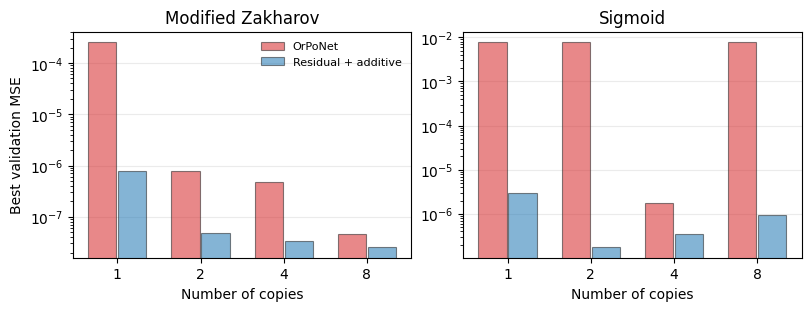

In [6]:
def plot_copies(ax, name):
    positions = np.arange(len(COPIES))
    ax.bar(
        positions - 0.18,
        results[name]["OrPoNet"],
        width=0.34,
        color="#d62728",
        edgecolor="#222222",
        linewidth=0.8,
        alpha=0.55,
        label="OrPoNet",
    )
    ax.bar(
        positions + 0.18,
        results[name]["Residual OrPoNet"],
        width=0.34,
        color="#1f77b4",
        edgecolor="#222222",
        linewidth=0.8,
        alpha=0.55,
        label="Residual + additive",
    )
    ax.set(title=name, xlabel="Number of copies", yscale="log")
    ax.set_xticks(positions, labels=COPIES)
    ax.grid(True, axis="y", alpha=0.25)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
plot_copies(axes[0], "Modified Zakharov")
axes[0].set_ylabel("Best validation MSE")
axes[0].legend(frameon=False, fontsize=8)
plot_copies(axes[1], "Sigmoid")
plt.show()
